In [20]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict  
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import PromptTemplate
from pydantic import BaseModel, Field


In [21]:
load_dotenv()
model = ChatGoogleGenerativeAI(
    model = "gemini-3.5-flash-lite"
)

In [22]:
class essayState(TypedDict):
    essay : str
    cot_marks: int
    cot_feedback : str

    doa_marks : int
    doa_feedback : str

    language_marks : int
    language_feedback : int

    final_feedback : str
    final_marks : int

In [23]:
class cotEvaluation(BaseModel):
    cot_feedback: str = Field(
        description="Detailed feedback on the clarity of thought in the essay"
    )

    cot_marks: int = Field(
        description="Score for clarity of thought, from 0 to 10",
        ge=0,
        le=10
    )

def cot(state : essayState):
    essay = state['essay']
    prompt = f'''You are an experienced evaluator at UPSC exam and evaluating the follow essay\n
    {essay}\n
    Evaluate the feedback and give a feedback on the essay on the basis of its clarity of thought and rate it ott of 10 '''

    structured_model = model.with_structured_output(cotEvaluation)
    result = structured_model.invoke(prompt)

    return {
            "cot_feedback": result.cot_feedback,
            "cot_marks": result.cot_marks
        }

In [24]:
class langEvaluation(BaseModel):
    language_feedback: str = Field(
        description="Detailed feedback on the language in the essay"
    )

    language_marks: int = Field(
        description="Score for language, from 0 to 10",
        ge=0,
        le=10
    )

def language(state : essayState):
    essay = state['essay']
    prompt = f'''You are an experienced evaluator at UPSC exam and evaluating the follow essay\n
    {essay}\n
    Evaluate the feedback and give a feedback on the essay on the basis of its language and rate it out of 10 '''

    structured_model = model.with_structured_output(langEvaluation)
    result = structured_model.invoke(prompt)

    return {
            "language_feedback": result.language_feedback,
            "language_marks": result.language_marks
        }

In [25]:
class doaEvaluation(BaseModel):
    doa_feedback: str = Field(
        description="Detailed feedback on the depth of analysis in the essay"
    )

    doa_marks: int = Field(
        description="Score for depth of analysis, from 0 to 10",
        ge=0,
        le=10
    )

def doa(state : essayState):
    essay = state['essay']
    prompt = f'''You are an experienced evaluator at UPSC exam and evaluating the follow essay\n
    {essay}\n
    Evaluate the feedback and give a feedback on the essay on the basis of its depth of analysis and rate it out of 10 '''

    structured_model = model.with_structured_output(doaEvaluation)
    result = structured_model.invoke(prompt)

    return {
            "doa_feedback": result.doa_feedback,
            "doa_marks": result.doa_marks
        }

In [26]:
def final_feedback(state : essayState):
    cot_feedback = state['cot_feedback']
    doa_feedback = state['doa_feedback']
    language_feedback = state['language_feedback']

    prompt = '''
        based upon the following feedbacks on\n
        clarity of analysis --- {cot_feedback}\n
        depth of analysis --- {doa_feedback}\n
        language --- {language_feedback}\n
        Create a feedback that should be shared to the writter so he can improve himself in overall terms.'''

    result = model.invoke(prompt)

    return {
        'final_feedback' : result.content
    }
    

In [27]:
def final_marks(state : essayState):
    marks = (state['cot_marks'] + state['doa_marks'] + state['language_marks']) / 3
    return{
        'final_marks' : marks
    }

In [29]:
graph = StateGraph(essayState)

graph.add_node('cot', cot)
graph.add_node('doa', doa)
graph.add_node('language', language)

graph.add_node('final_feedback', final_feedback)
graph.add_node('final_marks', final_marks)


graph.add_edge(START, 'cot')
graph.add_edge(START, 'doa')
graph.add_edge(START, 'language')

graph.add_edge('cot', 'final_feedback')
graph.add_edge('doa', 'final_feedback')
graph.add_edge('language', 'final_feedback')

graph.add_edge('final_feedback', 'final_marks')
graph.add_edge('final_marks', END)

workflow = graph.compile()

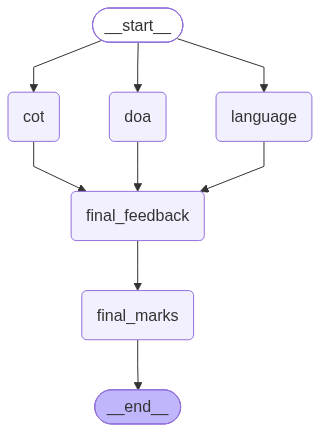

In [30]:
from  IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [32]:
initial_state = {
    'essay' : '''# Terrorism

Terrorism is one of the major problems in the world today. It means using violence and creating fear among people to achieve certain goals. Many countries have faced terrorist attacks, which have caused the death of innocent people and damage to public property. Terrorism is not only a problem for one country but affects the whole world.

There are many reasons behind terrorism. One of the main reasons is poverty and unemployment, as some people may get influenced by wrong groups when they do not have proper opportunities. Another reason is religious and political extremism. Some organisations motivate people to take violent steps in the name of religion or their country. Lack of education and awareness can also make the situation worse.

Terrorism has many negative effects on society. It creates fear among people and makes them feel unsafe in their own country. Due to terrorist attacks, many families lose their loved ones. It also affects the economy because tourists may stop visiting places where attacks happen. The government has to spend a lot of money on security instead of using it for development. Terrorism can also create tension between different communities.

India has also faced the problem of terrorism many times. The Mumbai attacks of 2008 were one of the major terrorist attacks in the country. Such incidents show that the country needs better security arrangements. The government has taken many steps to control terrorism, but more efforts are still required.

There are several ways to reduce terrorism. First, the government should improve security and take strict action against terrorists. Second, education and employment opportunities should be provided to people so that they do not get influenced by extremist groups. Third, countries should cooperate with each other to share information and prevent terrorist activities. People should also maintain peace and avoid spreading hatred against other communities.

Social media should also be used carefully because some people spread false information and encourage violence through it. The government should take action against those who misuse technology for terrorist activities.

In conclusion, terrorism is a serious problem that affects peace and development. It cannot be solved by the government alone, and people must also contribute to maintaining peace and unity. If countries work together and provide better opportunities to their citizens, terrorism can be controlled to some extent. Everyone should understand the importance of peace and live together with mutual respect.'''
}

final_state = workflow.invoke(initial_state)

print(final_state['final_marks'])
print(final_state['final_feedback'])

6.0
[{'type': 'text', 'text': 'Here is a comprehensive and constructive feedback summary that you can share with the writer. It synthesizes the three specific areas into actionable advice for overall improvement.\n\n***\n\n**Dear Writer,**\n\nThank you for your recent submission. To help you grow and elevate the quality of your future work, here is a consolidated feedback review based on three key pillars: **Clarity of Analysis**, **Depth of Analysis**, and **Language**. \n\n### 1. Clarity of Analysis ({cot_feedback})\n* **Area for Improvement:** Your reasoning needs to be easier for the reader to follow from point to point. \n* **How to improve:** \n  * Ensure your logical flow is seamless. Avoid jumping between ideas without clear transitions.\n  * State your main arguments upfront and use supporting evidence immediately to back them up.\n  * Ask yourself: *Can a reader unfamiliar with this topic easily follow my train of thought?* If the answer is no, simplify your structure and bre